# MAKEMORE

### Checking out the names dataset

In [8]:
words = open('names.txt','r').read().splitlines()

In [9]:
words[0:9]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper']

In [10]:
len(words)

32033

In [11]:
#Find min length of word
min(len(w) for w in words)

2

In [12]:
#Find max length of word

In [13]:
max(len(w) for w in words)

15

Training - How it works ? 
- So, in a string like **isabella** ,we have multiple training examples at a character level prediction
- i is a good starting char
- s follows i
- a follows is
- b follows isa
- e follows isab
- l follows isabe
- l follows isabel
- a follows isabell
- "\n" or endChar follows isabella

So this is how the training set looks like for one word

## Implementing Bigram

[Bigram Definition](https://en.wikipedia.org/wiki/Bigram)
- So basically bi meaning 2, the probability that two characters occur together
- Thus, given a single char, what is the next char that occurs
- for isabella this becomes
- i as a start or after the start char
- s after i, a after s, b after a ... endChar after a

The probability of the character increases and that can be used to predict the next character, knowing a singe character before it.

#### Now let's see how data would look like

In [21]:
#For the first 3 words
for w in words[:3]:
    for char1,char2 in zip(w,w[1:]):
        print(char1,char2)
    print("\n") #To separate words

e m
m m
m a


o l
l i
i v
v i
i a


a v
v a




We also need to know what character to start with and when to end
- We can have two special characters \<S> and \<E>
- Now, for \<S> what is the probability distribtion of characters after it
- For, \<E> what is the probability of \<E> after a particular char
- Thus we can have a start symbol \<S>
- And, an end symbol \<E>

In [20]:
#For the first 3 words
for w in words[:3]:
    
    chars = ['<S>'] + list(w) + ['<E>']
    
    for char1, char2 in zip(chars,chars[1:]):
        print(char1,char2)
    
    print("\n")

<S> e
e m
m m
m a
a <E>


<S> o
o l
l i
i v
v i
i a
a <E>


<S> a
a v
v a
a <E>




Now we can store the probability in a dictionary
- Basically counting the combinations of two characters occuring together

In [25]:
#For the first 3 words, but counting and storing in a dictionary

b = {}
for w in words[:3]:
    
    chars = ['<S>'] + list(w) + ['<E>']
    
    for char1, char2 in zip(chars,chars[1:]):
        
        bigram = (char1,char2)
        b[bigram] = b.get(bigram,0)+1
        
b

{('<S>', 'e'): 1,
 ('e', 'm'): 1,
 ('m', 'm'): 1,
 ('m', 'a'): 1,
 ('a', '<E>'): 3,
 ('<S>', 'o'): 1,
 ('o', 'l'): 1,
 ('l', 'i'): 1,
 ('i', 'v'): 1,
 ('v', 'i'): 1,
 ('i', 'a'): 1,
 ('<S>', 'a'): 1,
 ('a', 'v'): 1,
 ('v', 'a'): 1}

Running it for the entire dataset

In [28]:
b = {}
for w in words:
    
    chars = ['<S>'] + list(w) + ['<E>']
    
    for char1, char2 in zip(chars,chars[1:]):
        
        bigram = (char1,char2)
        b[bigram] = b.get(bigram,0)+1

In [29]:
b

{('<S>', 'e'): 1531,
 ('e', 'm'): 769,
 ('m', 'm'): 168,
 ('m', 'a'): 2590,
 ('a', '<E>'): 6640,
 ('<S>', 'o'): 394,
 ('o', 'l'): 619,
 ('l', 'i'): 2480,
 ('i', 'v'): 269,
 ('v', 'i'): 911,
 ('i', 'a'): 2445,
 ('<S>', 'a'): 4410,
 ('a', 'v'): 834,
 ('v', 'a'): 642,
 ('<S>', 'i'): 591,
 ('i', 's'): 1316,
 ('s', 'a'): 1201,
 ('a', 'b'): 541,
 ('b', 'e'): 655,
 ('e', 'l'): 3248,
 ('l', 'l'): 1345,
 ('l', 'a'): 2623,
 ('<S>', 's'): 2055,
 ('s', 'o'): 531,
 ('o', 'p'): 95,
 ('p', 'h'): 204,
 ('h', 'i'): 729,
 ('<S>', 'c'): 1542,
 ('c', 'h'): 664,
 ('h', 'a'): 2244,
 ('a', 'r'): 3264,
 ('r', 'l'): 413,
 ('l', 'o'): 692,
 ('o', 't'): 118,
 ('t', 't'): 374,
 ('t', 'e'): 716,
 ('e', '<E>'): 3983,
 ('<S>', 'm'): 2538,
 ('m', 'i'): 1256,
 ('a', 'm'): 1634,
 ('m', 'e'): 818,
 ('<S>', 'h'): 874,
 ('r', 'p'): 14,
 ('p', 'e'): 197,
 ('e', 'r'): 1958,
 ('r', '<E>'): 1377,
 ('e', 'v'): 463,
 ('v', 'e'): 568,
 ('l', 'y'): 1588,
 ('y', 'n'): 1826,
 ('n', '<E>'): 6763,
 ('b', 'i'): 217,
 ('i', 'g'): 428,


Seeing the most likely combinations in the dataset

In [30]:
sorted(b.items(), key = lambda kv : kv[1], reverse = True)

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

##### A better way to store the data
- a 2D array would be much better
- the rows can be the first character
- the columns the second character
- the values can indicate **the probability that the second character follows the first character**

In [31]:
import torch

By default the datatype is float32, but since we are storing counts we can use int32


In [36]:
a = torch.zeros((3,5))
ab

tensor([[0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.]])

In [37]:
a.dtype

torch.float32

Switching the datatype(dtype) to int32

In [51]:
a = torch.zeros((3,5), dtype = torch.int32)
a

tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0]], dtype=torch.int32)

In [52]:
a.dtype

torch.int32

Playing/Exploring torch tensors

In [53]:
a[1,3] = 1
a

tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 1, 0],
        [0, 0, 0, 0, 0]], dtype=torch.int32)

In [54]:
a[2,4] += 1
a

tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 1, 0],
        [0, 0, 0, 0, 1]], dtype=torch.int32)

#### Making actual data structure
- So we have 26 characters + 2 special characters(\<S> - start, \<E> - end)
- Thus we need a 28x28 tensor

In [57]:
N = torch.zeros((28,28),dtype = torch.int32)
N

tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0

#### Adding the counts into 2D Array N

- But we need someway to convert from characters to int for indexing
- So we need a lookup table

In [62]:
#Getting all the characters
#words should have all
chars = sorted(list(set("".join(words))))
chars

['a',
 'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'i',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'y',
 'z']

In [65]:
#Now we can create a mapping from s(trings) to i(ntegers)
stoi = {s:i for i,s in enumerate(chars)}
stoi['<S>'] = 26
stoi['<E>'] = 27
stoi

{'a': 0,
 'b': 1,
 'c': 2,
 'd': 3,
 'e': 4,
 'f': 5,
 'g': 6,
 'h': 7,
 'i': 8,
 'j': 9,
 'k': 10,
 'l': 11,
 'm': 12,
 'n': 13,
 'o': 14,
 'p': 15,
 'q': 16,
 'r': 17,
 's': 18,
 't': 19,
 'u': 20,
 'v': 21,
 'w': 22,
 'x': 23,
 'y': 24,
 'z': 25,
 '<S>': 26,
 '<E>': 27}

In [66]:
for w in words:
    
    chars = ['<S>'] + list(w) + ['<E>']
    
    for char1,char2 in zip(chars,chars[1:]): 
        
        N[stoi[char1],stoi[char2]] +=1
        
N

tensor([[ 556,  541,  470, 1042,  692,  134,  168, 2332, 1650,  175,  568, 2528,
         1634, 5438,   63,   82,   60, 3264, 1118,  687,  381,  834,  161,  182,
         2050,  435,    0, 6640],
        [ 321,   38,    1,   65,  655,    0,    0,   41,  217,    1,    0,  103,
            0,    4,  105,    0,    0,  842,    8,    2,   45,    0,    0,    0,
           83,    0,    0,  114],
        [ 815,    0,   42,    1,  551,    0,    2,  664,  271,    3,  316,  116,
            0,    0,  380,    1,   11,   76,    5,   35,   35,    0,    0,    3,
          104,    4,    0,   97],
        [1303,    1,    3,  149, 1283,    5,   25,  118,  674,    9,    3,   60,
           30,   31,  378,    0,    1,  424,   29,    4,   92,   17,   23,    0,
          317,    1,    0,  516],
        [ 679,  121,  153,  384, 1271,   82,  125,  152,  818,   55,  178, 3248,
          769, 2675,  269,   83,   14, 1958,  861,  580,   69,  463,   50,  132,
         1070,  181,    0, 3983],
        [ 242,    0,

- We can see last row is compeletely empty
- This validates that after \<E> end character no other character comes

#### Plotting using matplotlib for better visualization

In [68]:
import matplotlib.pyplot as plt
%matplotlib inline

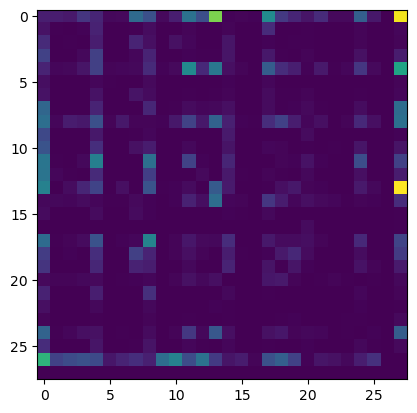

In [69]:
plt.imshow(N)

- Still looking ugly?
- Let's making it really beautiful

In [72]:
#Integer to string mapping
itos = {i:s for s,i in stoi.items()}
itos

{0: 'a',
 1: 'b',
 2: 'c',
 3: 'd',
 4: 'e',
 5: 'f',
 6: 'g',
 7: 'h',
 8: 'i',
 9: 'j',
 10: 'k',
 11: 'l',
 12: 'm',
 13: 'n',
 14: 'o',
 15: 'p',
 16: 'q',
 17: 'r',
 18: 's',
 19: 't',
 20: 'u',
 21: 'v',
 22: 'w',
 23: 'x',
 24: 'y',
 25: 'z',
 26: '<S>',
 27: '<E>'}

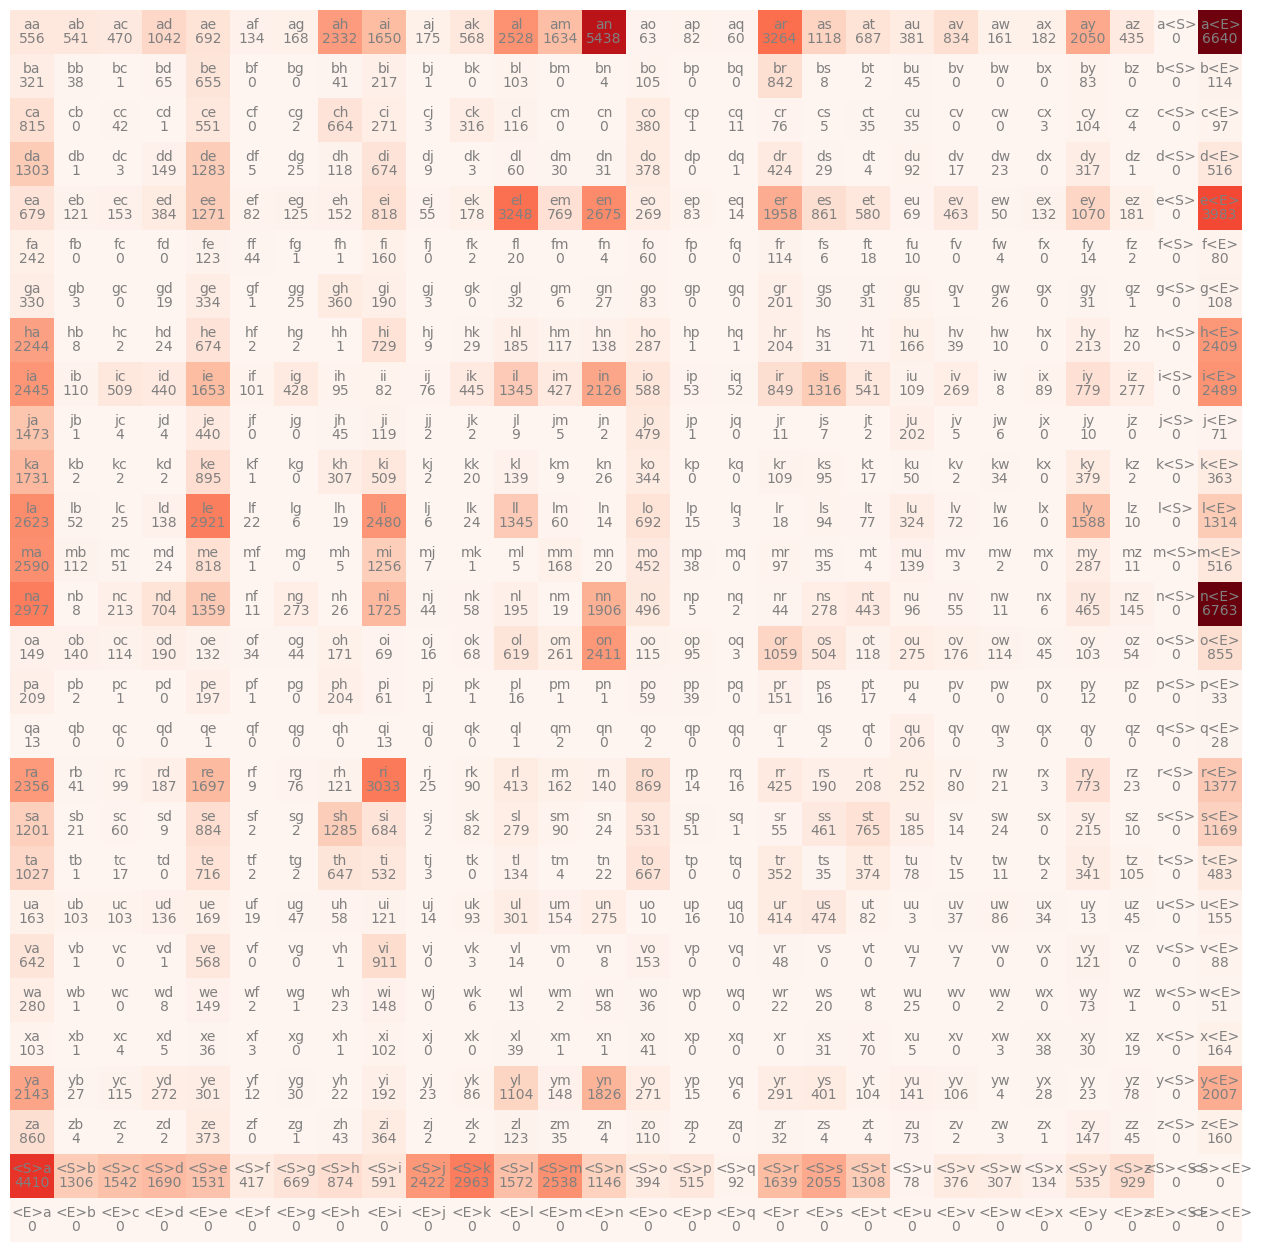

In [82]:
plt.figure(figsize = (16,16))
plt.imshow(N,cmap = 'Reds')
for i in range(28):
    for j in range(28):
        chstr = itos[i] + itos[j]
        plt.text(j,i,chstr,ha="center",va="bottom",color="grey") #Show the bigram
        plt.text(j,i,N[i,j].item(),ha="center",va="top",color="grey") #Show the count
plt.axis('off');

In [ ]:
"c"